# Function Transformer & Data Transformers in Sklearn

`sklearn.preprocessing` gives us three main transformer families for reshaping feature distributions:

```
                        sklearn
                           |
        ┌──────────────────┼──────────────────┐
        |                  |                  |
FunctionTransformer   PowerTransformer   QuantileTransformer
        |                  |
   ├─ Log transform    ├─ Box-Cox
   ├─ Reciprocal       └─ Yeo-Johnson
   ├─ Square/Sqrt
   └─ Custom function
```

---

## 1. FunctionTransformer

**What it is:** A wrapper that turns *any* Python function into a scikit-learn transformer (with `fit`/`transform`), so you can plug it into a `Pipeline`. It doesn't learn anything from the data — it's stateless (no `mean_`, `scale_`, etc. get computed).

**Common variants:**
| Transform | Function | Use case |
|---|---|---|
| Log | `np.log1p` | Right-skewed data, reduces influence of large values |
| Reciprocal | `1/x` | Inverse relationships |
| Square root | `np.sqrt` | Mild right-skew, count data |
| Square | `np.square` | Left-skewed data |
| Custom | any user-defined `f(x)` | Domain-specific transforms |

```python
import numpy as np
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log1p, validate=True)
X_transformed = log_transformer.fit_transform(X)

# Custom function example
def custom_transform(x):
    return np.where(x > 0, np.sqrt(x), x)

custom_ft = FunctionTransformer(custom_transform)
```

**Note:** `np.log1p` is preferred over `np.log` when your data can contain zeros, since `log(0)` is undefined but `log1p(0) = log(1) = 0`.

---

## 2. PowerTransformer

**What it is:** Applies a power transform to make data **more Gaussian-like** — useful when you have skewed features and want to stabilize variance / make the distribution closer to normal (helps linear models, PCA, etc.).
it have inbuild StandardScaler
Two methods:

### a) Box-Cox
- Formula (for λ ≠ 0): `y = (x^λ - 1) / λ`
- **Requires strictly positive data** (x > 0)
- Finds the optimal λ automatically via maximum likelihood

### b) Yeo-Johnson
- An extension of Box-Cox that **works with zero and negative values too**
- Generally the safer default when you're not sure your data is strictly positive

```python
from sklearn.preprocessing import PowerTransformer

# Box-Cox — data must be > 0
pt_boxcox = PowerTransformer(method='box-cox', standardize=True)
X_bc = pt_boxcox.fit_transform(X_positive_only)

# Yeo-Johnson — handles 0 and negatives
pt_yj = PowerTransformer(method='yeo-johnson', standardize=True)
X_yj = pt_yj.fit_transform(X)
```

By default `standardize=True`, so output also has zero mean and unit variance.

---

## 3. QuantileTransformer

**What it is:** Maps features to a **uniform** or **normal** distribution using the empirical quantile function — i.e., it ranks the data and redistributes it to follow the target distribution.

```python
from sklearn.preprocessing import QuantileTransformer

qt = QuantileTransformer(output_distribution='normal', n_quantiles=1000)
X_qt = qt.fit_transform(X)
```

**Key properties:**
- Non-linear transformation → **robust to outliers** (they get squashed toward the tails of the target distribution)
- Distorts correlations/relationships between features that are linear in original space (since it's rank-based, not linear)
- `n_quantiles` controls resolution; should generally be ≤ number of samples

---

## Quick comparison

| Transformer | Learns from data? | Handles negatives? | Best for |
|---|---|---|---|
| FunctionTransformer | No (stateless) | Depends on function | Simple, known transforms (log, sqrt, custom) |
| PowerTransformer (Box-Cox) | Yes (learns λ) | No, must be > 0 | Making positive skewed data Gaussian |
| PowerTransformer (Yeo-Johnson) | Yes (learns λ) | Yes | Same as above, but data has 0/negatives |
| QuantileTransformer | Yes (learns quantiles) | Yes | Heavy outliers, arbitrary distributions |

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np


In [2]:
try:
    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/titanic.csv',
                     index_col='PassengerId',
                     usecols=['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

                     )
except Exception as e:
    print(e)

In [3]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
887,0,2,male,27.0,0,0,13.0000,S
888,1,1,female,19.0,0,0,30.0000,S
889,0,3,female,NaN,1,2,23.4500,S


## Log Transformation

Log transformation changes the scale of a feature.

It is especially useful when a feature grows multiplicatively or is highly right-skewed.

A key property of logarithms is:

**Multiplication becomes addition**

For example:

```text
Original scale:

1  →  2  →  4  →  8
    ×2     ×2     ×2


Log scale:

log(1)  →  log(2)  →  log(4)  →  log(8)
   0        0.69        1.39        2.08

             +0.69       +0.69       +0.69

In [4]:
df['Fare'].skew()

4.787316519674893

In [5]:
df['Fare'].info()

<class 'pandas.core.series.Series'>
Index: 891 entries, 1 to 891
Series name: Fare
Non-Null Count  Dtype  
--------------  -----  
891 non-null    float64
dtypes: float64(1)
memory usage: 13.9 KB


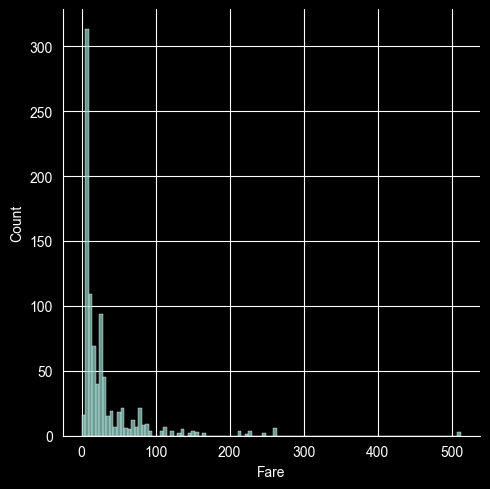

In [6]:
sns.displot(data=df,x='Fare', kde=False)

In [7]:
from sklearn.preprocessing import FunctionTransformer

np.log do only log but it cannot to log of 0
np.log1p add 1 then do log so no 0 error present

In [8]:
lt = FunctionTransformer(func=np.log1p)
df[['Fare']] = lt.fit_transform(df[['Fare']])

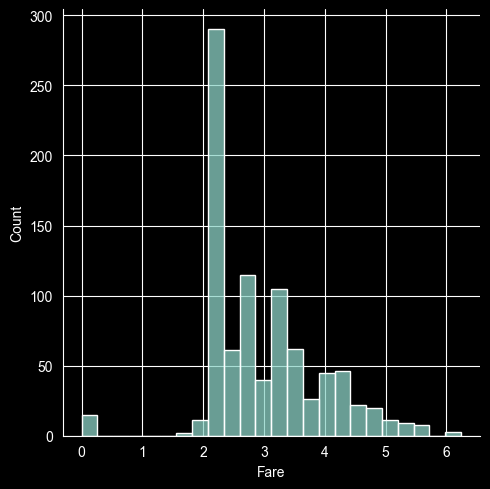

In [9]:
sns.displot(data=df,x='Fare', kde=False)

In [10]:
df[['Fare']].skew()

Fare    0.394928
dtype: float64

square transformer
sq(x^2) for left skewed

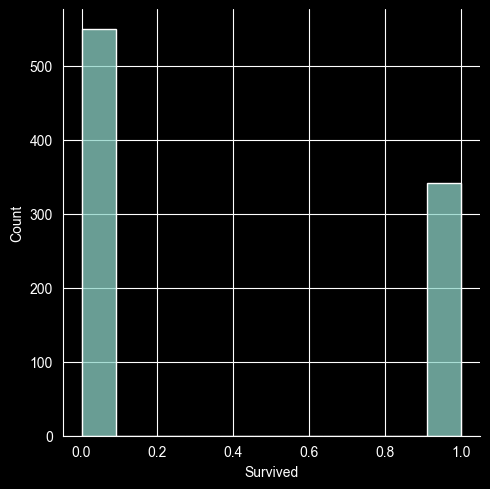

In [11]:
sns.displot(data=df,x='Survived', kde=False)

In [12]:
df['Survived'].skew()

0.4785234382949897

Pipeline A-Z

In [13]:
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
try:
    df = pd.read_csv(r'/home/mukul/Main/Basic_DataScience-4ML/assets/data/transformer.csv',
    usecols=['income','debt','city','education','target'],
    header=0,
    engine='python',
    on_bad_lines='error',

                       )

except Exception as e:
    print(e)


In [15]:
df

,income,debt,city,education,target
0,78184.06,53779.45,Mumbai,Bachelor,0
1,44149.66,48731.86,Delhi,High School,0
2,89563.04,54663.54,Chennai,Bachelor,0
3,196910.61,50490.57,Mumbai,High School,1
4,40499.31,60218.08,Bangalore,Bachelor,0
...,...,...,...,...,...
1995,130994.88,46637.84,Mumbai,Bachelor,1
1996,48820.67,60796.56,Delhi,High School,0
1997,22608.72,50615.33,Delhi,High School,0
1998,43175.05,8131.79,Mumbai,Master,0


EDA

No Missing Value

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   income     2000 non-null   float64
 1   debt       2000 non-null   float64
 2   city       2000 non-null   object 
 3   education  2000 non-null   object 
 4   target     2000 non-null   int64  
dtypes: float64(2), int64(1), object(2)
memory usage: 78.2+ KB


income, debt have skewness and have no duplicated value but both are having a heavy amount of outliers

In [17]:
df.describe()

,income,debt,target
count,2.000000e+03,2000.000000,2000.000000
mean,7.771850e+04,43012.835610,0.421500
std,8.831200e+04,14534.880794,0.493923
min,2.704410e+03,5000.000000,0.000000
25%,2.854916e+04,36318.502500,0.000000
50%,5.205214e+04,47000.670000,0.000000
75%,9.245335e+04,54042.945000,1.000000
max,1.602758e+06,62825.690000,1.000000


In [18]:
df['income'].skew()

5.166246513923311

In [19]:
df['debt'].skew()

-1.1218565274781354

In [20]:
df.duplicated().sum()

0

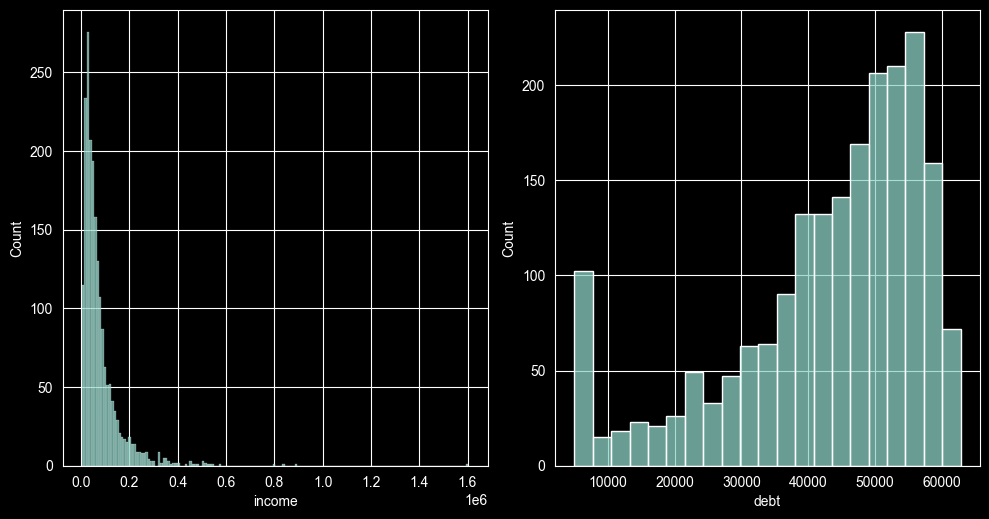

In [21]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
sns.histplot(x=df['income'], kde=False)

plt.subplot(2,2,2)
sns.histplot(x=df['debt'], kde=False)

plt.tight_layout()
plt.show()

<Axes: xlabel='debt'>

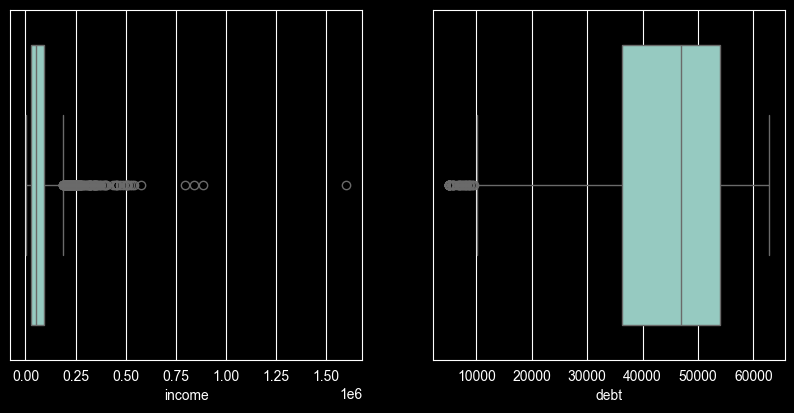

In [22]:
plt.figure(figsize=(10,10))

plt.subplot(2,2,1)
sns.boxplot(data=df,x=df['income'])
plt.subplot(2,2,2)
sns.boxplot(data=df,x=df['debt'])

PreProcessing

In [23]:
from sklearn.model_selection import  train_test_split
from sklearn.compose import  ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler,OneHotEncoder,OrdinalEncoder
from sklearn.impute import  SimpleImputer
from sklearn.preprocessing import FunctionTransformer

In [24]:
x = df.drop('target', axis=1)
y = df['target']
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [25]:
num_pipeline_1 = make_pipeline(
                FunctionTransformer(np.log1p),
                StandardScaler(),

)
num_pipeline_2 = make_pipeline(
                FunctionTransformer(np.square),
)
col_pipeline_1 = make_pipeline(
                OneHotEncoder(handle_unknown='ignore',sparse_output=False),
)
col_pipeline_2 = make_pipeline(
                OrdinalEncoder(categories=[['High School','Bachelor','Master','PhD']]),
)


In [26]:
cr = ColumnTransformer(
    transformers=[
        ('num_pipeline_1', num_pipeline_1, ['income']),
        ('num_pipeline_2', num_pipeline_2, ['debt']),
        ('col_pipeline_1', col_pipeline_1, ['city']),
        ('col_pipeline_2', col_pipeline_2, ['education']),
    ]
)

In [27]:
cr.fit_transform(x_train)
cr.transform(x_test)

array([[-1.65455973e-01,  2.69171183e+09,  0.00000000e+00, ...,
         0.00000000e+00,  1.00000000e+00,  0.00000000e+00],
       [-1.91468058e-01,  3.37345716e+09,  1.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       [ 1.48383019e+00,  1.45141493e+09,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [ 1.70700052e+00,  3.36332723e+09,  0.00000000e+00, ...,
         1.00000000e+00,  0.00000000e+00,  1.00000000e+00],
       [-8.95572356e-02,  1.69019326e+09,  0.00000000e+00, ...,
         0.00000000e+00,  1.00000000e+00,  1.00000000e+00],
       [ 1.89615179e-02,  2.53605406e+09,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  1.00000000e+00]])

In [28]:
model = make_pipeline(
    cr,
    LogisticRegression(max_iter=1000),

)

In [29]:
from sklearn.metrics import accuracy_score

model.fit(x_train, y_train)

y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.58


we can achieve more accuracy with more concepts butthis is maximum with the tools we learned yet 


Box-cox transformation

$$
y(\lambda) = \begin{cases}
\lambda y^{\lambda - 1} & \text{if } \lambda \neq 0 \\
\ln(y) & \text{if } \lambda = 0
\end{cases}
$$

but lambda cannot be 0 and 1 so we use yeo-jhonson

In [30]:
from sklearn.preprocessing import PowerTransformer

transformer = PowerTransformer(method='box-cox',standardize=False)

# X_train_transformed = transformer.fit_transform(x_train)
# X_test_transformed = transformer.transform(x_test)